In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("graduados_2020_2025.csv")
print(df.shape)
print(df.columns.tolist())
print(df["sexo"].value_counts(dropna=False))

(273485, 15)
['institucion', 'sector', 'caracter_institucion', 'departamento', 'programa', 'nivel_academico', 'nivel_formacion', 'area_conocimiento', 'sexo', 'anio', 'semestre', 'graduados', 'departamento_normalizado', 'nivel_formacion_normalizado', 'sector_normalizado']
sexo
MASCULINO     137583
FEMENINO      135890
NO BINARIO        12
Name: count, dtype: int64


In [2]:
# Usar la versión normalizada de la columna si existe
def col(nombre):
    return f"{nombre}_normalizado" if f"{nombre}_normalizado" in df.columns else nombre

llaves = ["anio", "institucion", col("sector"), "caracter_institucion",
          col("departamento"), "programa", col("nivel_formacion"), "area_conocimiento"]

sexo = df["sexo"].astype(str).str.upper().str.strip()
df["mujeres"] = np.where(sexo.str.startswith(("MUJER", "FEMEN")), df["graduados"], 0)
df["hombres"] = np.where(sexo.str.startswith(("HOMBRE", "MASCU")), df["graduados"], 0)

prog = df.groupby(llaves, dropna=False)[["mujeres", "hombres"]].sum().reset_index()
prog["total"] = prog["mujeres"] + prog["hombres"]
prog = prog[prog["total"] > 0].copy()
prog["prop_mujeres"] = prog["mujeres"] / prog["total"]

print(prog.shape)
prog["prop_mujeres"].describe()

(82819, 12)


count    82819.000000
mean         0.514890
std          0.299511
min          0.000000
25%          0.307692
50%          0.538462
75%          0.730769
max          1.000000
Name: prop_mujeres, dtype: float64

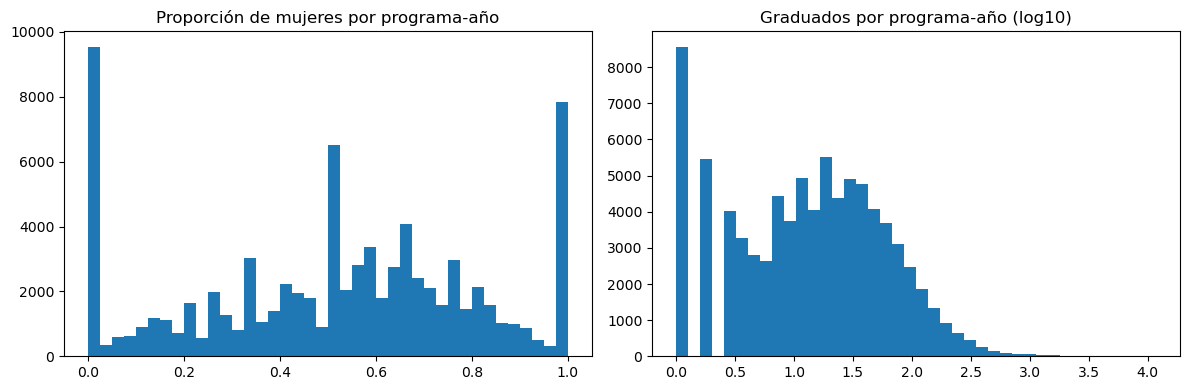

Programas-año con menos de 5 graduados: 25.8%
Programas-año con menos de 10 graduados: 40.0%
Programas-año con menos de 30 graduados: 67.8%
Con 0% mujeres:   11.4%
Con 100% mujeres: 9.3%
Media simple:     51.49%
Media ponderada:  56.10%


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(prog["prop_mujeres"], bins=40)
ax[0].set_title("Proporción de mujeres por programa-año")
ax[1].hist(np.log10(prog["total"]), bins=40)
ax[1].set_title("Graduados por programa-año (log10)")
plt.tight_layout()
plt.show()

for corte in [5, 10, 30]:
    print(f"Programas-año con menos de {corte} graduados: {(prog['total'] < corte).mean():.1%}")

print(f"Con 0% mujeres:   {(prog['prop_mujeres'] == 0).mean():.1%}")
print(f"Con 100% mujeres: {(prog['prop_mujeres'] == 1).mean():.1%}")
print(f"Media simple:     {prog['prop_mujeres'].mean():.2%}")
print(f"Media ponderada:  {prog['mujeres'].sum() / prog['total'].sum():.2%}")

anio                           0.001
caracter_institucion           0.005
departamento_normalizado       0.015
nivel_formacion_normalizado    0.019
sector_normalizado             0.021
institucion                    0.176
area_conocimiento              0.281
dtype: float64


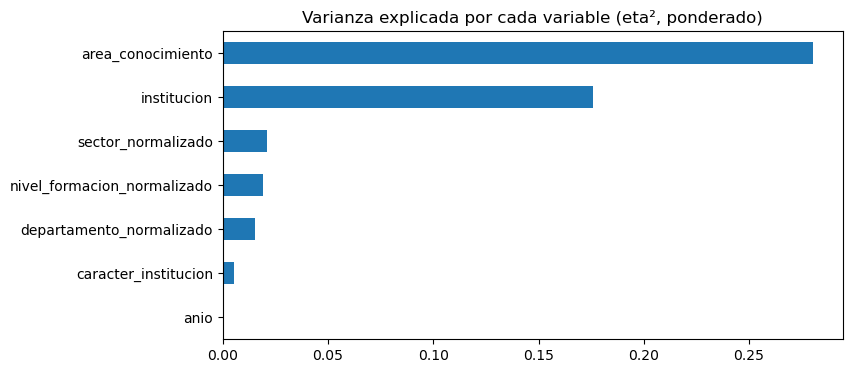

In [4]:
def eta2(data, var, y="prop_mujeres", w="total"):
    d = data.dropna(subset=[var]).copy()
    d["yw"] = d[y] * d[w]
    media = d["yw"].sum() / d[w].sum()
    g = d.groupby(var).agg(yw=("yw", "sum"), w=(w, "sum"))
    g["m"] = g["yw"] / g["w"]
    ss_entre = (g["w"] * (g["m"] - media) ** 2).sum()
    ss_total = (d[w] * (d[y] - media) ** 2).sum()
    return ss_entre / ss_total

variables = ["area_conocimiento", col("nivel_formacion"), col("sector"),
             "caracter_institucion", col("departamento"), "anio", "institucion"]

res = pd.Series({v: eta2(prog, v) for v in variables}).sort_values()
print(res.round(3))

res.plot(kind="barh", figsize=(8, 4), title="Varianza explicada por cada variable (eta², ponderado)")
plt.show()

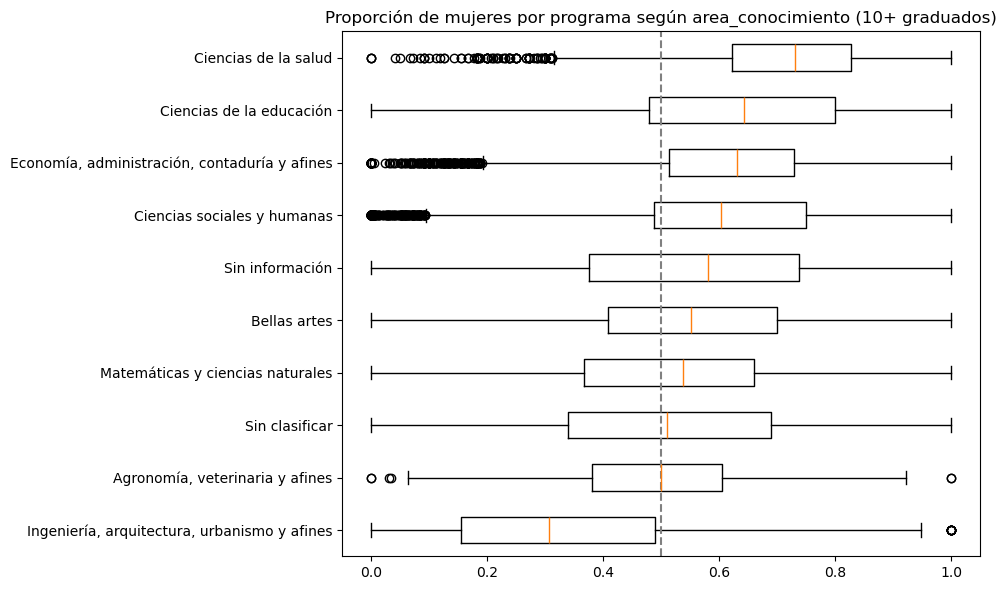

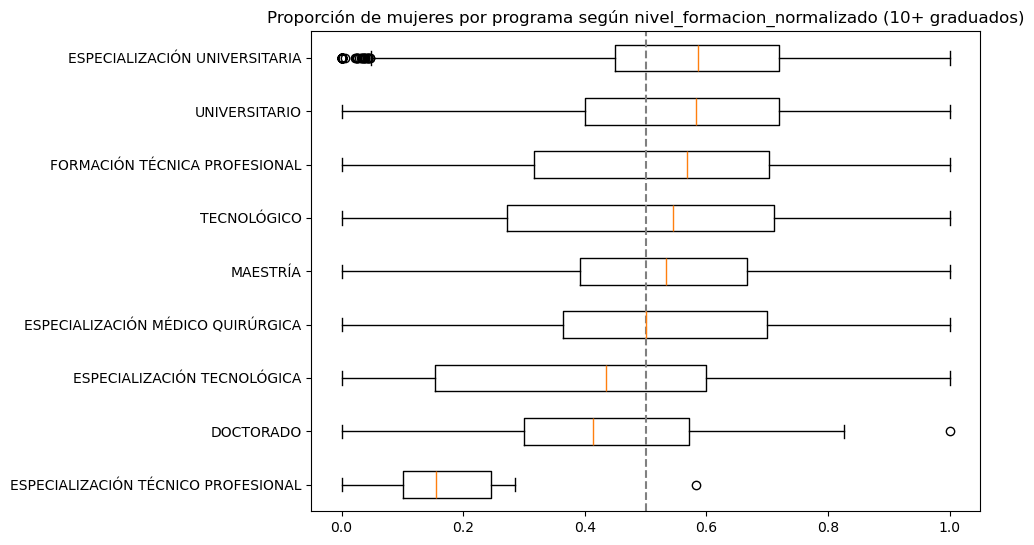

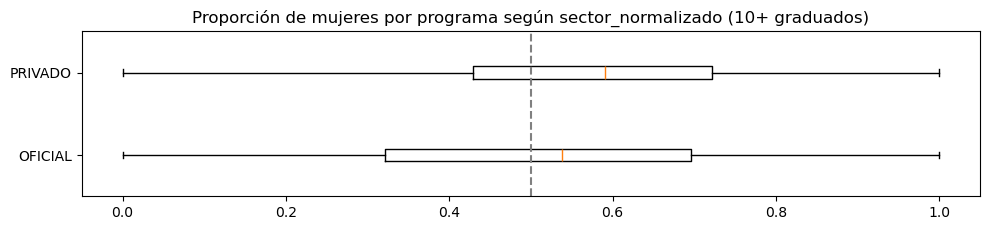

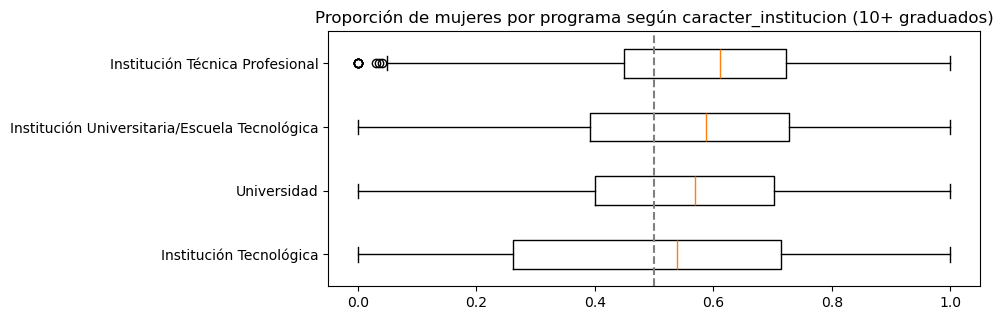

In [5]:
base = prog[prog["total"] >= 10]

for var in ["area_conocimiento", col("nivel_formacion"), col("sector"), "caracter_institucion"]:
    orden = base.groupby(var)["prop_mujeres"].median().sort_values().index
    datos = [base.loc[base[var] == k, "prop_mujeres"] for k in orden]
    plt.figure(figsize=(10, 0.45 * len(orden) + 1.5))
    plt.boxplot(datos, vert=False)
    plt.yticks(range(1, len(orden) + 1), orden)
    plt.axvline(0.5, linestyle="--", color="grey")
    plt.title(f"Proporción de mujeres por programa según {var} (10+ graduados)")
    plt.tight_layout()
    plt.show()

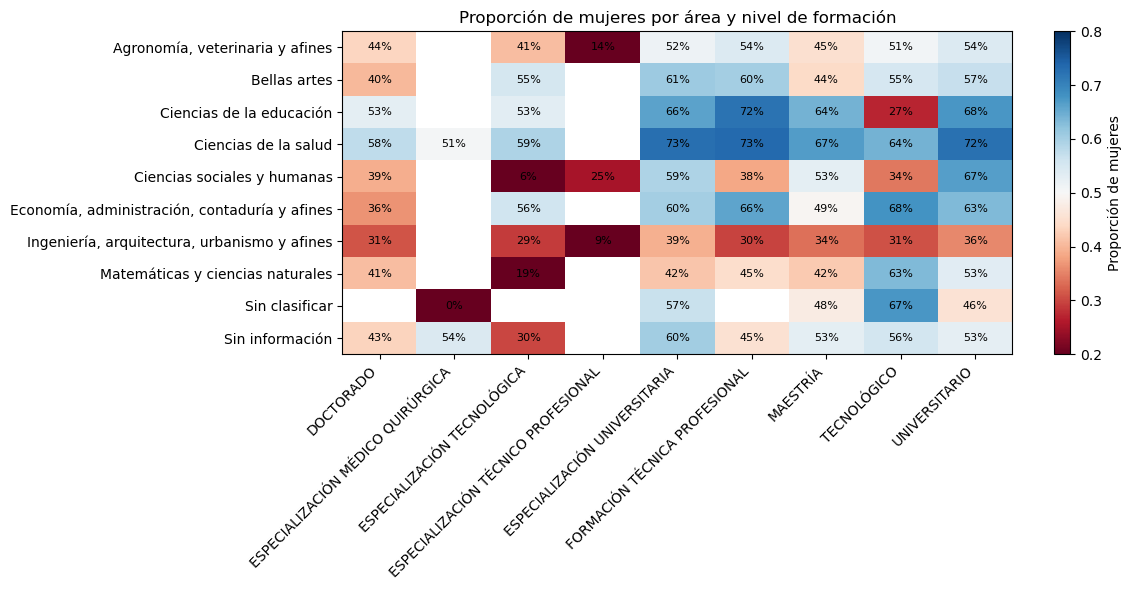

In [6]:
t = prog.groupby(["area_conocimiento", col("nivel_formacion")])[["mujeres", "total"]].sum()
tabla = (t["mujeres"] / t["total"]).unstack()

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(tabla, cmap="RdBu", vmin=0.2, vmax=0.8, aspect="auto")
ax.set_xticks(range(len(tabla.columns)), tabla.columns, rotation=45, ha="right")
ax.set_yticks(range(len(tabla.index)), tabla.index)
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        v = tabla.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="Proporción de mujeres")
plt.title("Proporción de mujeres por área y nivel de formación")
plt.tight_layout()
plt.show()

id_prog = [c for c in llaves if c != "anio"]
prog = prog.sort_values(id_prog + ["anio"])
prog["prop_anio_anterior"] = prog.groupby(id_prog, dropna=False)["prop_mujeres"].shift(1)

p = prog.dropna(subset=["prop_anio_anterior"])
p = p[p["total"] >= 10]
print(f"Correlación año t vs año t-1: {p['prop_mujeres'].corr(p['prop_anio_anterior']):.3f}")

anios_por_prog = prog.groupby(id_prog, dropna=False)["anio"].nunique()
print(anios_por_prog.value_counts().sort_index())

plt.scatter(p["prop_anio_anterior"], p["prop_mujeres"], s=5, alpha=0.2)
plt.xlabel("Proporción año anterior")
plt.ylabel("Proporción año actual")
plt.title("Persistencia de la proporción de mujeres por programa")
plt.show()

prog.to_csv("programas_anio.csv", index=False, encoding="utf-8-sig")

## Conclusiones de la exploración

**1. Unidad de análisis.** La base se agregó a 82.819 registros programa-año. El panel es desbalanceado: 6.927 programas aparecen en los seis años, pero 5.550 aparecen solo una vez (programas nuevos, cerrados o años sin graduados). Se excluyeron 12 registros con sexo "No binario", por ser un volumen muy bajo para modelar.

**2. Variable objetivo y ruido por tamaño.** El 40 % de los programas-año tiene menos de 10 graduados. El 11,4 % tiene 0 % de mujeres y el 9,3 % tiene 100 %, valores extremos que en buena parte se explican por el tamaño pequeño. La media simple (51,5 %) es menor que la ponderada (56,1 %), lo que indica que los programas pequeños tienen menor participación femenina. Para el modelo se ponderará por número de graduados o se filtrarán los programas con menos de 10 graduados.

**3. Qué variables explican la participación femenina (eta²).** El área de conocimiento es, por mucho, la variable más relevante (28,1 % de la varianza), seguida de la institución (17,6 %). El sector (2,1 %), el nivel de formación (1,9 %), el departamento (1,5 %) y el carácter de la institución (0,5 %) explican poco por sí solos, y el año prácticamente nada (0,1 %), lo que confirma que la participación nacional es estable entre 2020 y 2025.

**4. Alta dispersión dentro de cada área.** En Ingeniería la mediana es 31 %, pero la mitad central de los programas va de 15 % a 49 %. En Ciencias de la salud la mediana es 73 % (rango intercuartil de 62 % a 83 %). El área marca el nivel general, pero no basta: hay que incluir variables del programa y de la institución.

**5. Interacción área x nivel.** La caída de mujeres en el posgrado no es igual en todas las áreas. En Economía y administración pasa de 63 % en pregrado universitario a 36 % en doctorado, y en Ciencias sociales de 67 % a 39 %. En Ingeniería se mantiene estable y baja (31 % a 36 %) en todos los niveles. Como el efecto de una variable depende de la otra, se justifica usar modelos que capturen interacciones (árboles de decisión, random forest o boosting).

**6. Persistencia en el tiempo.** La correlación entre la proporción de mujeres de un programa en un año y en el año anterior es de 0,80. El historial del programa es un predictor muy fuerte, por lo que el modelo debe validarse de forma temporal (entrenar con 2020-2023 y evaluar con 2024-2025) para evitar fuga de información.

**Implicaciones para el modelo.** Variable objetivo: proporción de mujeres por programa-año, ponderada por graduados. Predictores principales: área, institución, nivel y su interacción. Validación: temporal.